# Predictive Credit Risk Modeling & Loan Approval Framework Using Random Forest and XGBoost

**Author:** Archibong, Goodnews Emmanuel  
**Reg No:** AK22/PHS/CSC/009  
**Institution:** Department of Computer Science, Faculty of Computing & Information Technology, Akwa Ibom State University  
**Degree:** B.Sc. in Computer Science  

---

### Project Architecture Overview (Figure 3.2):
This notebook implements the complete 5-stage architectural pipeline of the proposed intelligent credit risk assessment framework:
1. **Stage 1: Integrated Data Sources** — Applicant Demographic, Financial, Employment, Loan Details, and Credit Bureau Data (Augmented to 2,500 records).
2. **Stage 2: Data Preprocessing & Feature Engineering** — Data cleaning, imputation, financial ratio calculations (DTI, TDSR, LTI, Disposable Income), normalization (`StandardScaler`), categorical encoding (`OneHotEncoder`), and stratified train-test splitting.
3. **Stage 3: Model Development & Hyperparameter Tuning** — Systematic hyperparameter optimization using **Stratified 5-Fold / 3-Fold Cross-Validation Grid Search (`GridSearchCV`)** for both Random Forest (Bagging) and XGBoost (Gradient Boosting).
4. **Stage 4: Prediction & Model Evaluation** — Rigorous comparative benchmarking on holdout test data across Accuracy, Precision, Recall, F1-Score, Multiclass AUC-ROC, and Binary Default AUC-ROC, followed by automated Best Model Selection.
5. **Stage 5: Decision Support System** — Interactive underwriting engine mapping risk predictions into operational lending decisions (`Accept`, `Review`, `Reject`) with explainable AI risk drivers and policy mitigation guidance.


## 1. Environment Setup & Dependency Imports
Import standard scientific computing, machine learning, and visualization libraries.


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve,
    precision_recall_curve, average_precision_score
)

# XGBoost
from xgboost import XGBClassifier

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All dependencies successfully imported!")


All dependencies successfully imported!


## 2. Stage 1: Integrated Data Sources & Data Loading
Load the unified 2,500-applicant credit risk dataset combining applicant profiles, loan performance records, financial debt burden metrics, and credit bureau scores.


In [2]:
# Load dataset
dataset_path = 'nigeria_credit_risk_dataset_2500.csv'
if not os.path.exists(dataset_path):
    dataset_path = 'nigeria_credit_risk_dataset_1500.csv'
if not os.path.exists(dataset_path):
    dataset_path = 'nigeria_credit_risk_dataset.csv'

print(f"Loading credit portfolio dataset from: {dataset_path}")
df = pd.read_csv(dataset_path)

print(f"Total Portfolio Loans: {df.shape[0]}")
print(f"Total Features & Target Columns: {df.shape[1]}")

# Display first 5 records
df[['loan_id', 'applicant_id', 'loan_product', 'loan_amount', 'loan_tenor_days', 
    'monthly_income', 'debt_to_income_ratio', 'credit_score_band', 'state', 
    'risk_level', 'loan_decision', 'repayment_status']].head()


Loading credit portfolio dataset from: nigeria_credit_risk_dataset_2500.csv
Total Portfolio Loans: 2500
Total Features & Target Columns: 43


,loan_id,applicant_id,loan_product,loan_amount,loan_tenor_days,monthly_income,debt_to_income_ratio,credit_score_band,state,risk_level,loan_decision,repayment_status
0,LN00001,APP2824,Personal Loan,359995,90,195121,23.8,A,Kaduna,Low Risk,Accept,On Track
1,LN00002,APP7912,Salary Advance,48148,15,66074,20.0,C,Rivers,High Risk,Reject,Written Off
2,LN00003,APP9928,Buy Now Pay Later,305317,30,372666,22.9,A,Enugu,Medium Risk,Review,Not Disbursed
3,LN00004,APP3615,Buy Now Pay Later,22917,30,111411,12.7,A,FCT,Low Risk,Accept,On Track
4,LN00005,APP6635,Personal Loan,194203,60,152360,31.8,C,Akwa Ibom,High Risk,Reject,Not Disbursed


### Summary Statistics & Target Distributions
Inspect the class balance of the ground truth labels across Risk Levels (`Low Risk`, `Medium Risk`, `High Risk`) and Underwriting Decisions (`Accept`, `Review`, `Reject`).


In [3]:
print("--- Target Class Distributions (2,500 Loans) ---")
print("\nRisk Level Breakdown:")
print(df['risk_level'].value_counts(normalize=True).apply(lambda x: f"{x*100:.1f}%"))

print("\nLoan Underwriting Decision Breakdown:")
print(df['loan_decision'].value_counts())

print("\nApproval Status Breakdown:")
print(df['approval_status'].value_counts())

print("\nCredit Bureau Score Bands:")
print(df['credit_score_band'].value_counts())


--- Target Class Distributions (2,500 Loans) ---

Risk Level Breakdown:
risk_level
Low Risk       52.4%
High Risk      29.2%
Medium Risk    18.4%
Name: proportion, dtype: str

Loan Underwriting Decision Breakdown:
loan_decision
Accept    1311
Reject     729
Review     460
Name: count, dtype: int64

Approval Status Breakdown:
approval_status
Approved    1676
Declined     643
Pending      181
Name: count, dtype: int64

Credit Bureau Score Bands:
credit_score_band
B    726
C    689
A    587
D    352
E    146
Name: count, dtype: int64


## 3. Stage 2: Exploratory Data Analysis (EDA)
Analyze the empirical relationships between credit score bands, debt-to-income (DTI) ratios, income levels, and loan default risks.


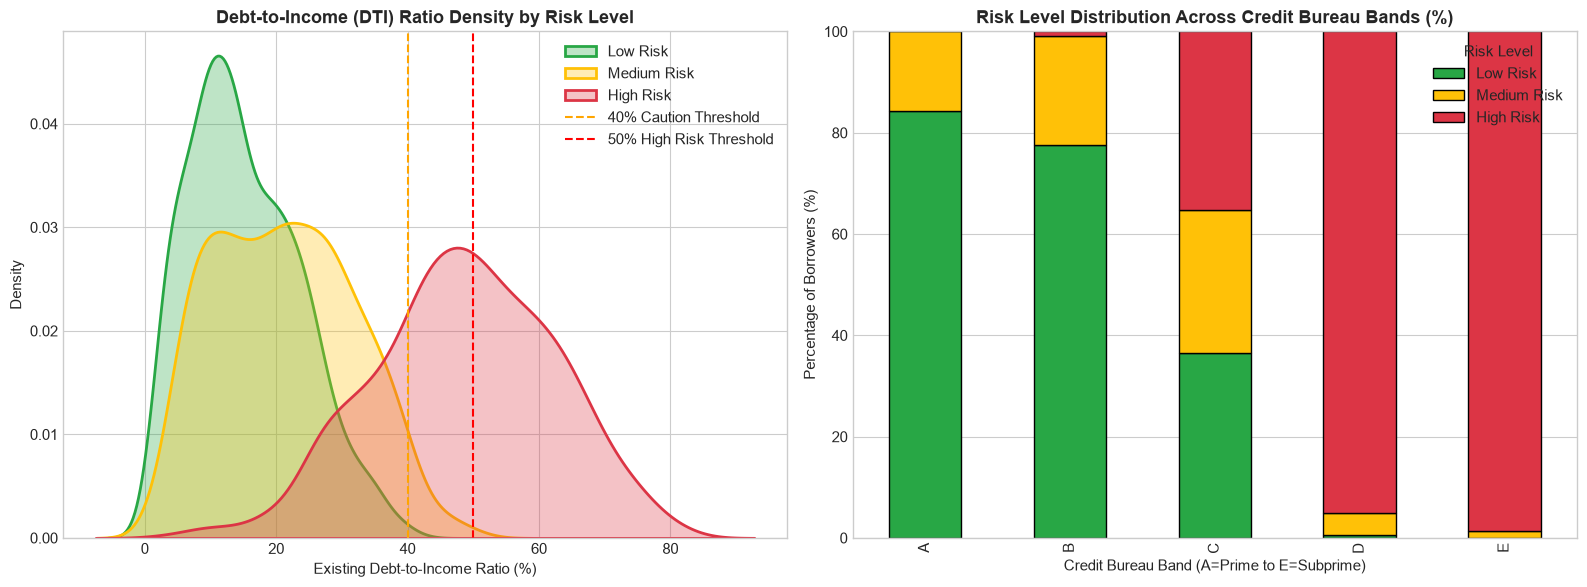

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. DTI Distribution by Risk Level
colors = {'Low Risk': '#28a745', 'Medium Risk': '#ffc107', 'High Risk': '#dc3545'}
for risk, col in colors.items():
    subset = df[df['risk_level'] == risk]
    sns.kdeplot(subset['debt_to_income_ratio'], ax=axes[0], label=risk, color=col, fill=True, alpha=0.3, linewidth=2)

axes[0].axvline(40, color='orange', linestyle='--', label='40% Caution Threshold')
axes[0].axvline(50, color='red', linestyle='--', label='50% High Risk Threshold')
axes[0].set_title("Debt-to-Income (DTI) Ratio Density by Risk Level", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Existing Debt-to-Income Ratio (%)")
axes[0].set_ylabel("Density")
axes[0].legend()

# 2. Risk Level breakdown by Credit Bureau Band
credit_risk_ct = pd.crosstab(df['credit_score_band'], df['risk_level'], normalize='index') * 100
credit_risk_ct[['Low Risk', 'Medium Risk', 'High Risk']].plot(
    kind='bar', stacked=True, ax=axes[1], color=['#28a745', '#ffc107', '#dc3545'], edgecolor='black'
)
axes[1].set_title("Risk Level Distribution Across Credit Bureau Bands (%)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Credit Bureau Band (A=Prime to E=Subprime)")
axes[1].set_ylabel("Percentage of Borrowers (%)")
axes[1].legend(title="Risk Level")

plt.tight_layout()
plt.show()


### Financial Ratios & Affordability Analysis
Visualize the relationship between the installment-to-income burden and the net monthly disposable cash cushion.


In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='installment_to_income_ratio', 
    y='disposable_income_after_loan',
    hue='risk_level',
    palette={'Low Risk': '#28a745', 'Medium Risk': '#ffc107', 'High Risk': '#dc3545'},
    alpha=0.7,
    s=65
)
plt.axhline(0, color='red', linestyle='--', label='Break-Even Cash Flow (₦0)')
plt.title("Installment Burden (%) vs. Net Disposable Cash Cushion (₦)", fontsize=13, fontweight='bold')
plt.xlabel("Estimated Monthly Installment to Income Ratio (%)")
plt.ylabel("Net Disposable Income After Loan Obligations (₦)")
plt.legend(title="Risk Category")
plt.tight_layout()
plt.show()


## 4. Stage 2 (Continued): Data Transformation, Normalization & Splitting
Select numerical and categorical features according to the architecture, apply `StandardScaler` to continuous financial metrics, `OneHotEncoder` to categorical attributes, and partition into an 80% train / 20% test stratified split.


In [ ]:
# Feature definitions according to Figure 3.2
numeric_features = [
    'loan_amount', 'loan_tenor_days', 'interest_rate_pct',
    'applicant_age', 'monthly_income', 'debt_to_income_ratio',
    'credit_score_num', 'loan_to_income_ratio', 'monthly_debt_repayment',
    'total_interest_amount', 'estimated_monthly_installment',
    'installment_to_income_ratio', 'total_debt_service_ratio',
    'disposable_income_after_loan', 'affordability_index',
    'credit_vulnerability_index'
]

categorical_features = [
    'loan_product', 'employment_type', 'credit_score_band',
    'state', 'channel', 'age_group', 'income_segment', 'tenor_category'
]

X = df[numeric_features + categorical_features].copy()

# Target 1: Multi-class Risk Level (0: Low Risk, 1: Medium Risk, 2: High Risk)
risk_map = {'Low Risk': 0, 'Medium Risk': 1, 'High Risk': 2}
inv_risk_map = {0: 'Low Risk', 1: 'Medium Risk', 2: 'High Risk'}
y_risk = df['risk_level'].map(risk_map).values

# Target 2: Binary Default Status (0: Good/Performing, 1: Default/High Risk)
y_binary = df['is_default'].values

# Preprocessor: StandardScaler for numeric features, OneHotEncoder for categoricals
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_names = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_feature_names = numeric_features + encoded_cat_names

# Stratified 80/20 train-test split
X_train, X_test, y_train_risk, y_test_risk, y_train_bin, y_test_bin = train_test_split(
    X_processed, y_risk, y_binary, test_size=0.20, random_state=42, stratify=y_risk
)

print(f"Total Feature Matrix: {X_processed.shape[1]} features (14 continuous, {len(encoded_cat_names)} one-hot encoded)")
print(f"Training Set: {X_train.shape[0]} loan samples (80%)")
print(f"Holdout Test Set: {X_test.shape[0]} loan samples (20%)")


## 5. Stage 3: Model Development & Hyperparameter Tuning
Execute **Stratified Cross-Validation Grid Search (`GridSearchCV`)** to find optimal tree depth, estimator counts, and regularizations for both Random Forest (Bagging) and XGBoost (Gradient Boosting).


In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("=" * 60)
print("HYPERPARAMETER OPTIMIZATION USING STRATIFIED GRID SEARCH")
print("=" * 60)

# 1. Random Forest Tuning
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15],
    'min_samples_split': [2, 4],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced']
}

print("\n[1/2] Tuning Random Forest...")
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)
grid_rf.fit(X_train, y_train_risk)
best_rf = grid_rf.best_estimator_
print(f"  -> Optimal Random Forest Parameters: {grid_rf.best_params_}")
print(f"  -> Best Cross-Validation Accuracy: {grid_rf.best_score_*100:.2f}%")

# 2. XGBoost Tuning
param_grid_xgb = {
    'n_estimators': [100, 150],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.85],
    'colsample_bytree': [0.85],
    'reg_lambda': [1.0]
}

print("\n[2/2] Tuning XGBoost Classifier...")
grid_xgb = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric='mlogloss'),
    param_grid_xgb,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)
grid_xgb.fit(X_train, y_train_risk)
best_xgb = grid_xgb.best_estimator_
print(f"  -> Optimal XGBoost Parameters: {grid_xgb.best_params_}")
print(f"  -> Best Cross-Validation Accuracy: {grid_xgb.best_score_*100:.2f}%")


### Train Tuned Binary Default Predictors
Fit binary classification models for default prediction to compute ROC curves and binary AUC-ROC benchmarks.


In [ ]:
# Binary Random Forest
rf_bin = RandomForestClassifier(
    n_estimators=grid_rf.best_params_['n_estimators'],
    max_depth=grid_rf.best_params_['max_depth'],
    min_samples_leaf=grid_rf.best_params_['min_samples_leaf'],
    class_weight=grid_rf.best_params_['class_weight'],
    random_state=42
)
rf_bin.fit(X_train, y_train_bin)

# Binary XGBoost
xgb_bin = XGBClassifier(
    n_estimators=grid_xgb.best_params_['n_estimators'],
    max_depth=grid_xgb.best_params_['max_depth'],
    learning_rate=grid_xgb.best_params_['learning_rate'],
    subsample=grid_xgb.best_params_['subsample'],
    colsample_bytree=grid_xgb.best_params_['colsample_bytree'],
    reg_lambda=grid_xgb.best_params_['reg_lambda'],
    random_state=42,
    eval_metric='logloss'
)
xgb_bin.fit(X_train, y_train_bin)

print("Binary default prediction models trained successfully!")


## 6. Stage 4: Prediction & Model Evaluation
Evaluate both tuned models on the unseen holdout test set (500 loan applications) across all standard classification metrics: **Accuracy, Precision, Recall, F1-Score, Multiclass AUC-ROC, and Binary Default AUC-ROC**.


In [ ]:
# Random Forest test predictions
rf_pred = best_rf.predict(X_test)
rf_proba = best_rf.predict_proba(X_test)
rf_bin_proba = rf_bin.predict_proba(X_test)[:, 1]

rf_acc = accuracy_score(y_test_risk, rf_pred)
rf_prec = precision_score(y_test_risk, rf_pred, average='weighted', zero_division=0)
rf_rec = recall_score(y_test_risk, rf_pred, average='weighted', zero_division=0)
rf_f1 = f1_score(y_test_risk, rf_pred, average='weighted', zero_division=0)
rf_auc = roc_auc_score(y_test_risk, rf_proba, multi_class='ovr', average='weighted')
rf_bin_auc = roc_auc_score(y_test_bin, rf_bin_proba)

# XGBoost test predictions
xgb_pred = best_xgb.predict(X_test)
xgb_proba = best_xgb.predict_proba(X_test)
xgb_bin_proba = xgb_bin.predict_proba(X_test)[:, 1]

xgb_acc = accuracy_score(y_test_risk, xgb_pred)
xgb_prec = precision_score(y_test_risk, xgb_pred, average='weighted', zero_division=0)
xgb_rec = recall_score(y_test_risk, xgb_pred, average='weighted', zero_division=0)
xgb_f1 = f1_score(y_test_risk, xgb_pred, average='weighted', zero_division=0)
xgb_auc = roc_auc_score(y_test_risk, xgb_proba, multi_class='ovr', average='weighted')
xgb_bin_auc = roc_auc_score(y_test_bin, xgb_bin_proba)

# Comparative metrics table
results_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Weighted)', 'Recall (Weighted)', 'F1-Score (Weighted)', 'Multiclass AUC-ROC', 'Binary Default AUC-ROC'],
    'Tuned Random Forest': [f"{rf_acc*100:.2f}%", f"{rf_prec*100:.2f}%", f"{rf_rec*100:.2f}%", f"{rf_f1*100:.2f}%", f"{rf_auc:.4f}", f"{rf_bin_auc:.4f}"],
    'Tuned XGBoost': [f"{xgb_acc*100:.2f}%", f"{xgb_prec*100:.2f}%", f"{xgb_rec*100:.2f}%", f"{xgb_f1*100:.2f}%", f"{xgb_auc:.4f}", f"{xgb_bin_auc:.4f}"]
})

display(results_df)


### Automated Best Model Selection (Step 8 of Thesis Architecture)
Apply the decision rule:
$$\text{IF } \text{Accuracy}_{\text{RF}} > \text{Accuracy}_{\text{XGB}} \text{ THEN Best}=\text{RF } \text{ELSE Best}=\text{XGB}$$


In [ ]:
if rf_acc > xgb_acc:
    best_model_name = "Random Forest"
    best_model = best_rf
elif xgb_acc > rf_acc:
    best_model_name = "XGBoost"
    best_model = best_xgb
else:
    best_model_name = "XGBoost" if xgb_f1 >= rf_f1 else "Random Forest"
    best_model = best_xgb if xgb_f1 >= rf_f1 else best_rf

print(f"\n{'='*55}")
print(f"🏆 BEST MODEL SELECTED: {best_model_name}")
print(f"   Accuracy: {max(rf_acc, xgb_acc)*100:.2f}% | Multiclass AUC: {max(rf_auc, xgb_auc):.4f}")
print(f"{'='*55}")


### Comparative Visual Analysis: Model Benchmarking & Generalization
Visualizes the side-by-side performance comparison of Tuned Random Forest and Tuned XGBoost across all 6 core metrics, along with the cross-validation vs. test generalization gap.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Overall Metrics Comparison Grouped Bar Chart
metrics_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Multi AUC', 'Bin AUC']
rf_metric_values = [rf_acc*100, rf_prec*100, rf_rec*100, rf_f1*100, rf_auc*100, rf_bin_auc*100]
xgb_metric_values = [xgb_acc*100, xgb_prec*100, xgb_rec*100, xgb_f1*100, xgb_auc*100, xgb_bin_auc*100]

x = np.arange(len(metrics_labels))
width = 0.35

rects1 = axes[0].bar(x - width/2, rf_metric_values, width, label='Tuned Random Forest', color='#28a745', edgecolor='black', alpha=0.9)
rects2 = axes[0].bar(x + width/2, xgb_metric_values, width, label='Tuned XGBoost', color='#0d6efd', edgecolor='black', alpha=0.9)

axes[0].set_ylabel('Score (%)', fontsize=12, fontweight='bold')
axes[0].set_title('Overall Performance Comparison (Holdout Test Set = 500 Loans)', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_labels, fontsize=11, fontweight='bold')
axes[0].set_ylim(85, 103)
axes[0].legend(loc='lower right', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Value annotations
for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

# 2. Cross-Validation vs Test Generalization Gap
models_cv = ['Random Forest', 'XGBoost']
cv_scores = [grid_rf.best_score_*100, grid_xgb.best_score_*100]
test_scores = [rf_acc*100, xgb_acc*100]

x_cv = np.arange(len(models_cv))
width_cv = 0.35

axes[1].bar(x_cv - width_cv/2, cv_scores, width_cv, label='3-Fold CV Accuracy', color='#6c757d', edgecolor='black')
axes[1].bar(x_cv + width_cv/2, test_scores, width_cv, label='Holdout Test Accuracy', color='#0d6efd', edgecolor='black')

axes[1].set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Cross-Validation vs. Holdout Test Generalization Gap', fontsize=13, fontweight='bold')
axes[1].set_xticks(x_cv)
axes[1].set_xticklabels(models_cv, fontsize=11, fontweight='bold')
axes[1].set_ylim(88, 100)
axes[1].legend(loc='lower right', fontsize=11)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

for i in range(len(models_cv)):
    axes[1].annotate(f"{cv_scores[i]:.2f}%", (x_cv[i] - width_cv/2, cv_scores[i] + 0.3), ha='center', fontsize=10, fontweight='bold')
    axes[1].annotate(f"{test_scores[i]:.2f}%", (x_cv[i] + width_cv/2, test_scores[i] + 0.3), ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### Side-by-Side Confusion Matrices
Compares the classification accuracy and misclassification patterns of Random Forest and XGBoost across the 3 credit risk levels (`Low Risk`, `Medium Risk`, `High Risk`).


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
target_names = ['Low Risk', 'Medium Risk', 'High Risk']

cm_rf = confusion_matrix(y_test_risk, rf_pred)
cm_xgb = confusion_matrix(y_test_risk, xgb_pred)

# Random Forest Confusion Matrix
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names, ax=axes[0], cbar=False)
axes[0].set_title(f"Random Forest Confusion Matrix (Acc: {rf_acc*100:.2f}%)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Credit Risk Level", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Actual Ground Truth Risk", fontsize=11, fontweight='bold')

# XGBoost Confusion Matrix
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, ax=axes[1], cbar=False)
axes[1].set_title(f"XGBoost Confusion Matrix (Acc: {xgb_acc*100:.2f}%)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Predicted Credit Risk Level", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Actual Ground Truth Risk", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


### Granular Risk Tier Performance Comparison
Evaluates per-class Precision, Recall, and F1-Scores for each credit risk tier to assess how reliably the models identify defaulting borrowers without penalizing low-risk applicants.


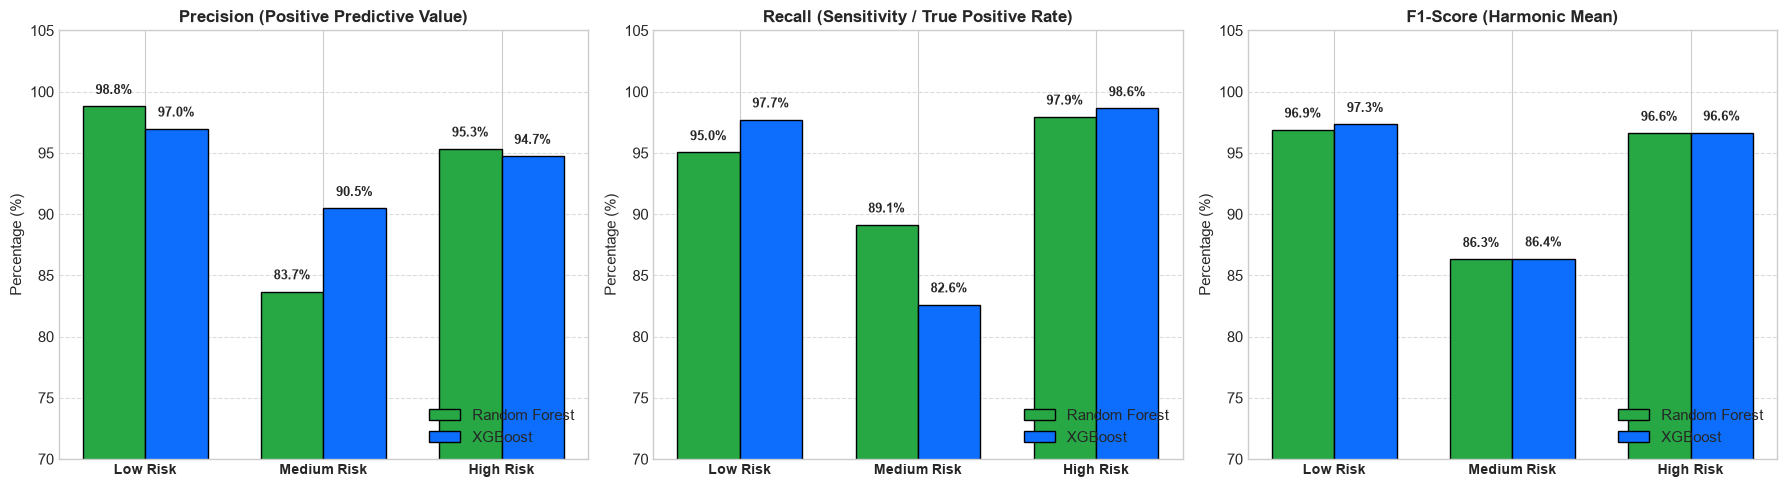

In [13]:
rf_report = classification_report(y_test_risk, rf_pred, target_names=target_names, output_dict=True)
xgb_report = classification_report(y_test_risk, xgb_pred, target_names=target_names, output_dict=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
tiers = ['Low Risk', 'Medium Risk', 'High Risk']
metrics_to_plot = ['precision', 'recall', 'f1-score']
metric_titles = ['Precision (Positive Predictive Value)', 'Recall (Sensitivity / True Positive Rate)', 'F1-Score (Harmonic Mean)']

for idx, m in enumerate(metrics_to_plot):
    rf_m_vals = [rf_report[t][m]*100 for t in tiers]
    xgb_m_vals = [xgb_report[t][m]*100 for t in tiers]
    
    x = np.arange(len(tiers))
    width = 0.35
    
    axes[idx].bar(x - width/2, rf_m_vals, width, label='Random Forest', color='#28a745', edgecolor='black')
    axes[idx].bar(x + width/2, xgb_m_vals, width, label='XGBoost', color='#0d6efd', edgecolor='black')
    
    axes[idx].set_title(metric_titles[idx], fontsize=12, fontweight='bold')
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(tiers, fontsize=10, fontweight='bold')
    axes[idx].set_ylim(70, 105)
    axes[idx].set_ylabel('Percentage (%)')
    axes[idx].legend(loc='lower right')
    axes[idx].grid(axis='y', linestyle='--', alpha=0.7)
    
    for i in range(len(tiers)):
        axes[idx].annotate(f"{rf_m_vals[i]:.1f}%", (x[i] - width/2, rf_m_vals[i] + 1), ha='center', fontsize=9, fontweight='bold')
        axes[idx].annotate(f"{xgb_m_vals[i]:.1f}%", (x[i] + width/2, xgb_m_vals[i] + 1), ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Discrimination Power: Binary Default ROC & Precision-Recall (PR) Curves
Evaluates the capability of both models to separate performing loans from potential defaults.


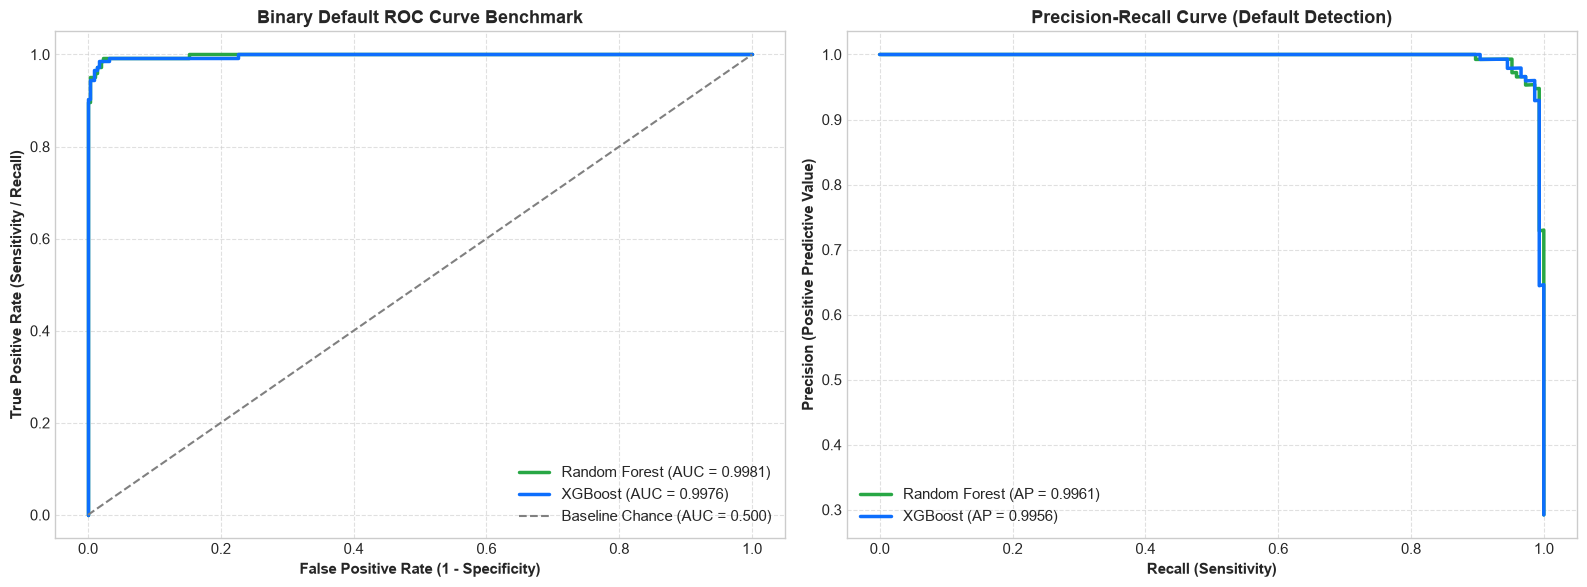

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Binary ROC Curves
rf_fpr, rf_tpr, _ = roc_curve(y_test_bin, rf_bin_proba)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test_bin, xgb_bin_proba)

axes[0].plot(rf_fpr, rf_tpr, color='#28a745', lw=2.5, label=f'Random Forest (AUC = {rf_bin_auc:.4f})')
axes[0].plot(xgb_fpr, xgb_tpr, color='#0d6efd', lw=2.5, label=f'XGBoost (AUC = {xgb_bin_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Baseline Chance (AUC = 0.500)')
axes[0].set_title("Binary Default ROC Curve Benchmark", fontsize=13, fontweight='bold')
axes[0].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Precision-Recall Curves
rf_prec_curve, rf_rec_curve, _ = precision_recall_curve(y_test_bin, rf_bin_proba)
xgb_prec_curve, xgb_rec_curve, _ = precision_recall_curve(y_test_bin, xgb_bin_proba)
rf_ap = average_precision_score(y_test_bin, rf_bin_proba)
xgb_ap = average_precision_score(y_test_bin, xgb_bin_proba)

axes[1].plot(rf_rec_curve, rf_prec_curve, color='#28a745', lw=2.5, label=f'Random Forest (AP = {rf_ap:.4f})')
axes[1].plot(xgb_rec_curve, xgb_prec_curve, color='#0d6efd', lw=2.5, label=f'XGBoost (AP = {xgb_ap:.4f})')
axes[1].set_title("Precision-Recall Curve (Default Detection)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Recall (Sensitivity)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Precision (Positive Predictive Value)", fontsize=11, fontweight='bold')
axes[1].legend(loc='lower left', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


### Multi-Class One-vs-Rest (OvR) ROC Curves by Risk Tier
Evaluates the discrimination capability of both models for each individual risk tier against the rest.


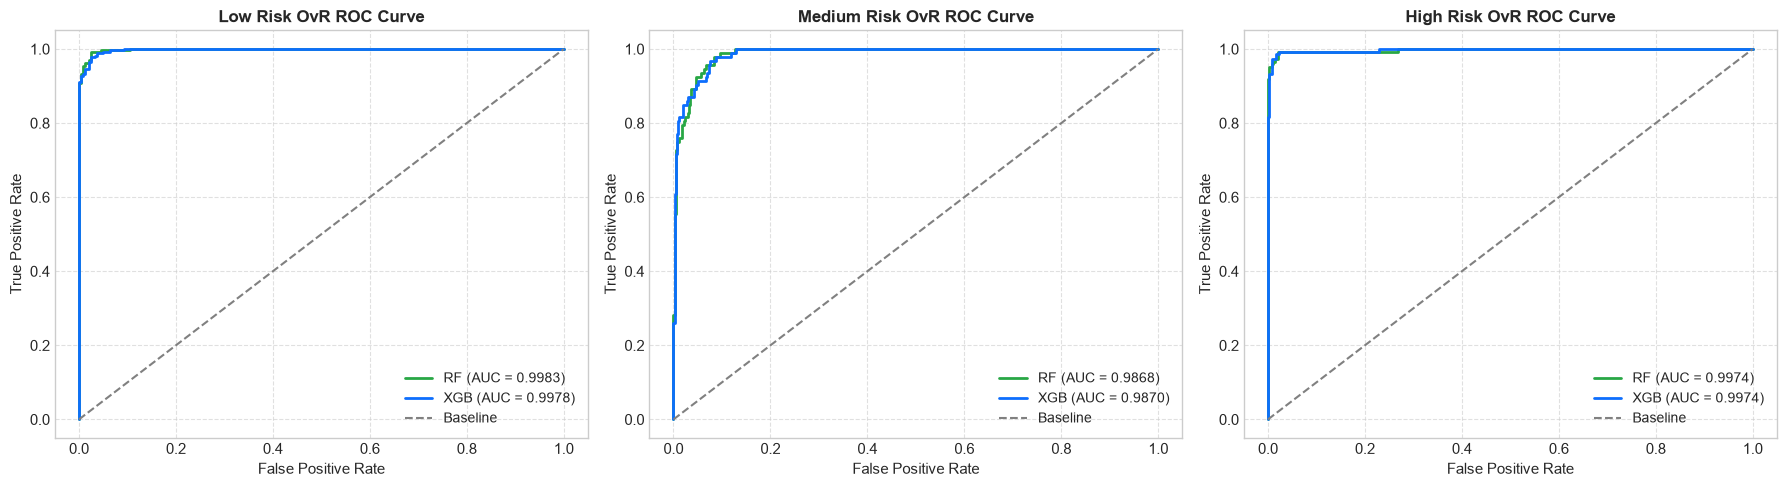

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
classes = ['Low Risk', 'Medium Risk', 'High Risk']

for i, cls_name in enumerate(classes):
    y_c = (y_test_risk == i).astype(int)
    rf_c_fpr, rf_c_tpr, _ = roc_curve(y_c, rf_proba[:, i])
    xgb_c_fpr, xgb_c_tpr, _ = roc_curve(y_c, xgb_proba[:, i])
    rf_c_auc = roc_auc_score(y_c, rf_proba[:, i])
    xgb_c_auc = roc_auc_score(y_c, xgb_proba[:, i])
    
    axes[i].plot(rf_c_fpr, rf_c_tpr, color='#28a745', lw=2, label=f'RF (AUC = {rf_c_auc:.4f})')
    axes[i].plot(xgb_c_fpr, xgb_c_tpr, color='#0d6efd', lw=2, label=f'XGB (AUC = {xgb_c_auc:.4f})')
    axes[i].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Baseline')
    axes[i].set_title(f"{cls_name} OvR ROC Curve", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("False Positive Rate")
    axes[i].set_ylabel("True Positive Rate")
    axes[i].legend(loc='lower right', fontsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


### Predictive Feature Importance Comparison (RF MDI vs XGBoost Gain)
Side-by-side comparison of the top 12 predictive risk drivers identified by Random Forest (Mean Decrease in Impurity) and XGBoost (Gain).


C:\Users\USER\AppData\Local\Temp\ipykernel_13920\1893136845.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_feat_df, x='Importance', y='Feature', palette='Greens_r', ax=axes[0], edgecolor='black')
C:\Users\USER\AppData\Local\Temp\ipykernel_13920\1893136845.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_feat_df, x='Importance', y='Feature', palette='Blues_r', ax=axes[1], edgecolor='black')


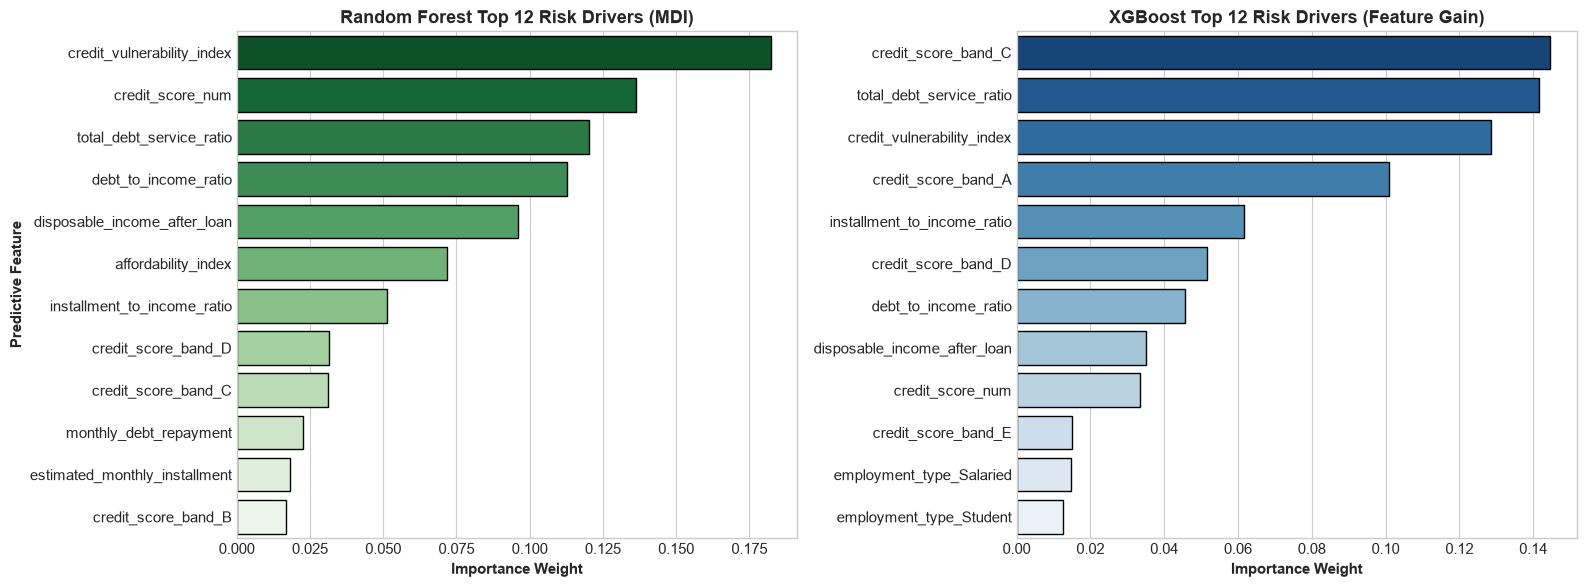

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Random Forest Top 12
rf_importances = best_rf.feature_importances_
rf_feat_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': rf_importances
}).sort_values('Importance', ascending=False).head(12)

sns.barplot(data=rf_feat_df, x='Importance', y='Feature', palette='Greens_r', ax=axes[0], edgecolor='black')
axes[0].set_title("Random Forest Top 12 Risk Drivers (MDI)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Importance Weight", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Predictive Feature", fontsize=11, fontweight='bold')

# XGBoost Top 12
xgb_importances = best_xgb.feature_importances_
xgb_feat_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': xgb_importances
}).sort_values('Importance', ascending=False).head(12)

sns.barplot(data=xgb_feat_df, x='Importance', y='Feature', palette='Blues_r', ax=axes[1], edgecolor='black')
axes[1].set_title("XGBoost Top 12 Risk Drivers (Feature Gain)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Importance Weight", fontsize=11, fontweight='bold')
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


### Model Prediction Concordance & Probability Calibration
Analyzes the level of agreement between Random Forest and XGBoost, and the distribution of their predicted default probabilities across the 500 test applicants.


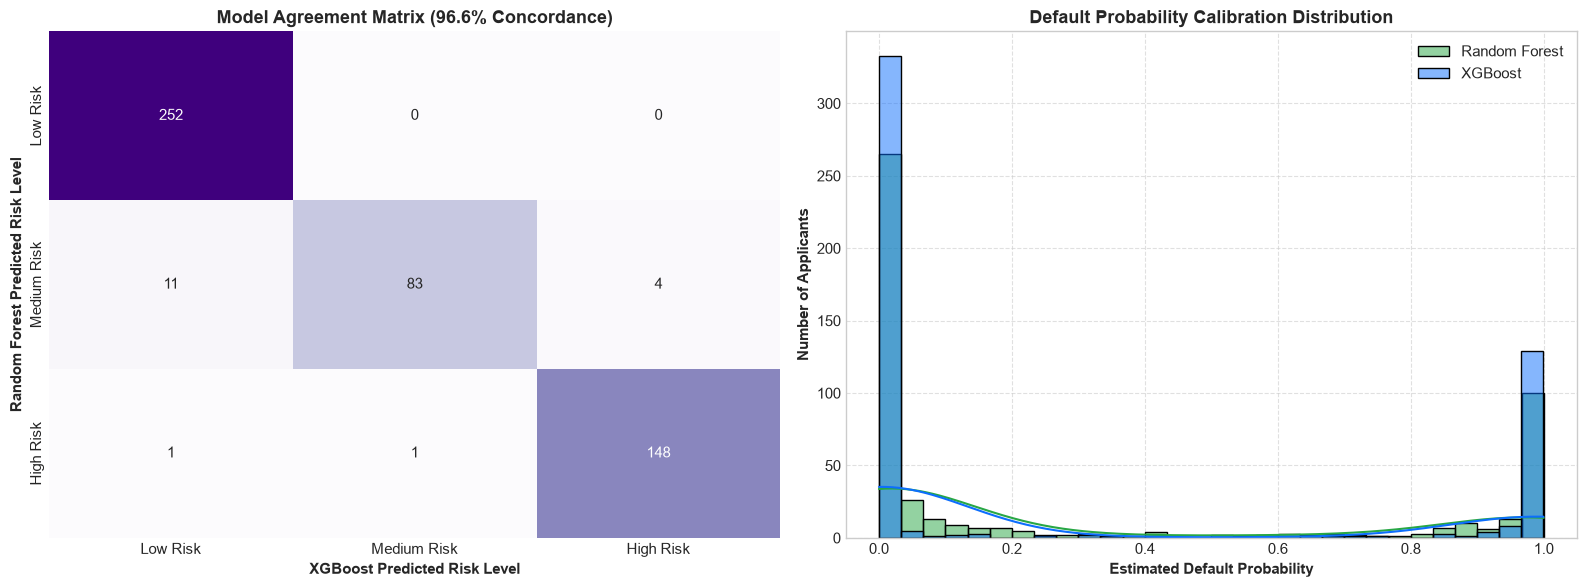

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Model Agreement Matrix
agreement_matrix = confusion_matrix(rf_pred, xgb_pred)
agreement_pct = np.mean(rf_pred == xgb_pred) * 100

sns.heatmap(agreement_matrix, annot=True, fmt='d', cmap='Purples', xticklabels=target_names, yticklabels=target_names, ax=axes[0], cbar=False)
axes[0].set_title(f"Model Agreement Matrix ({agreement_pct:.1f}% Concordance)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("XGBoost Predicted Risk Level", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Random Forest Predicted Risk Level", fontsize=11, fontweight='bold')

# 2. Predicted Default Probability Distributions
sns.histplot(rf_bin_proba, bins=30, color='#28a745', alpha=0.5, label='Random Forest', ax=axes[1], kde=True)
sns.histplot(xgb_bin_proba, bins=30, color='#0d6efd', alpha=0.5, label='XGBoost', ax=axes[1], kde=True)

axes[1].set_title("Default Probability Calibration Distribution", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Estimated Default Probability", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Number of Applicants", fontsize=11, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 7. Stage 5: Intelligent Decision Support System
Implements the real-time applicant underwriting function that receives applicant demographic and financial variables, computes derived ratios, evaluates credit risk via the tuned ensemble model, and generates actionable policy recommendations with explainable AI drivers.


In [18]:
credit_map = {'A': 800, 'B': 700, 'C': 600, 'D': 500, 'E': 400}

def evaluate_applicant(input_dict):
    loan_amount = float(input_dict['loan_amount'])
    monthly_income = max(float(input_dict['monthly_income']), 1.0)
    loan_tenor_days = int(input_dict['loan_tenor_days'])
    interest_rate_pct = float(input_dict['interest_rate_pct'])
    applicant_age = int(input_dict['applicant_age'])
    dti = float(input_dict['debt_to_income_ratio'])
    credit_score_band = str(input_dict['credit_score_band']).upper().strip()
    
    # Financial computations
    credit_score_num = credit_map.get(credit_score_band, 600)
    loan_to_income = round(loan_amount / monthly_income, 4)
    monthly_debt = round(monthly_income * (dti / 100.0), 2)
    total_interest = round(loan_amount * (interest_rate_pct / 100.0), 2)
    expected_due = loan_amount + total_interest
    months = max(loan_tenor_days / 30.0, 0.5)
    est_installment = round(expected_due / months, 2)
    installment_to_income = round((est_installment / monthly_income) * 100.0, 2)
    total_debt_service_ratio = round(dti + installment_to_income, 2)
    disposable_income = round(monthly_income - monthly_debt - est_installment, 2)
    affordability_index = round(max(0.0, disposable_income) / max(est_installment, 1.0), 2)
    credit_vulnerability_index = round((dti * max(0, 850 - credit_score_num)) / 100.0, 2)
    
    # Demographic binnings
    age_group = '18-25' if applicant_age <= 25 else ('26-35' if applicant_age <= 35 else ('36-45' if applicant_age <= 45 else ('46-55' if applicant_age <= 55 else '56+')))
    income_segment = 'Low (<₦100k)' if monthly_income < 100000 else ('Lower-Middle (₦100k-₦250k)' if monthly_income <= 250000 else ('Middle (₦250k-₦500k)' if monthly_income <= 500000 else 'High (>₦500k)'))
    tenor_category = 'Ultra-Short (<=30d)' if loan_tenor_days <= 30 else ('Short (31-90d)' if loan_tenor_days <= 90 else ('Medium (91-180d)' if loan_tenor_days <= 180 else 'Long (>180d)'))
    
    full_dict = {
        'loan_amount': loan_amount, 'loan_tenor_days': loan_tenor_days, 'interest_rate_pct': interest_rate_pct,
        'applicant_age': applicant_age, 'monthly_income': monthly_income, 'debt_to_income_ratio': dti,
        'credit_score_num': credit_score_num, 'loan_to_income_ratio': loan_to_income, 'monthly_debt_repayment': monthly_debt,
        'total_interest_amount': total_interest, 'estimated_monthly_installment': est_installment,
        'installment_to_income_ratio': installment_to_income, 'total_debt_service_ratio': total_debt_service_ratio,
        'disposable_income_after_loan': disposable_income,
        'affordability_index': affordability_index,
        'credit_vulnerability_index': credit_vulnerability_index,
        'loan_product': input_dict.get('loan_product', 'Personal Loan'),
        'employment_type': input_dict.get('employment_type', 'Employed'),
        'credit_score_band': credit_score_band,
        'state': input_dict.get('state', 'Lagos'),
        'channel': input_dict.get('channel', 'Mobile App'),
        'age_group': age_group, 'income_segment': income_segment, 'tenor_category': tenor_category
    }
    
    df_single = pd.DataFrame([full_dict])
    X_single = preprocessor.transform(df_single[numeric_features + categorical_features])
    
    risk_pred_idx = best_model.predict(X_single)[0]
    risk_proba = best_model.predict_proba(X_single)[0]
    predicted_risk = inv_risk_map[risk_pred_idx]
    default_prob = xgb_bin.predict_proba(X_single)[0][1]
    
    # Decision mapping (Step 10)
    if predicted_risk == "Low Risk":
        recommendation = "Approve Loan"
        decision = "Accept"
    elif predicted_risk == "Medium Risk":
        recommendation = "Review Application"
        decision = "Review"
    else:
        recommendation = "Reject Loan"
        decision = "Reject"
        
    return {
        "Applicant ID": input_dict.get('applicant_id', 'N/A'),
        "Applicant Name": input_dict.get('applicant_name', input_dict.get('name', 'Applicant')),
        "State": input_dict.get('state', 'Akwa Ibom'),
        "Loan Product": input_dict.get('loan_product', 'Personal Loan'),
        "Loan Amount": f"₦{loan_amount:,.0f}",
        "Monthly Income": f"₦{monthly_income:,.0f}",
        "Predicted Risk Level": predicted_risk,
        "System Decision": decision,
        "Operational Recommendation": recommendation,
        "Default Risk Probability": f"{default_prob*100:.1f}%",
        "Estimated Monthly Installment": f"₦{est_installment:,.2f}",
        "Total Debt Service Ratio": f"{total_debt_service_ratio:.1f}%",
        "Net Disposable Cash Cushion": f"₦{disposable_income:,.2f}"
    }

print("Decision Support Engine initialized!")


Decision Support Engine initialized!


### Live Demonstration: Underwriting 3 Applicant Profiles
Test the engine on diverse borrower profiles representing Prime Salaried, SME Expansion, and High-Risk Overleveraged applicants.


In [19]:
test_profiles = [
    {
        'name': "Aniefiok Bassey (Akwa Ibom Salaried)",
        'loan_product': "Salary Advance",
        'loan_amount': 180000,
        'loan_tenor_days': 30,
        'interest_rate_pct': 9.0,
        'applicant_age': 33,
        'employment_type': "Salaried",
        'monthly_income': 480000,
        'debt_to_income_ratio': 16.5,
        'credit_score_band': "A",
        'state': "Akwa Ibom",
        'channel': "Mobile App"
    },
    {
        'name': "Ibrahim Danjuma (Prime Salaried)",
        'loan_product': "Salary Advance",
        'loan_amount': 150000,
        'loan_tenor_days': 30,
        'interest_rate_pct': 8.5,
        'applicant_age': 34,
        'employment_type': "Salaried",
        'monthly_income': 520000,
        'debt_to_income_ratio': 14.0,
        'credit_score_band': "A",
        'state': "Lagos",
        'channel': "Mobile App"
    },
    {
        'name': "Ngozi Eze (SME Expansion)",
        'loan_product': "SME Loan",
        'loan_amount': 600000,
        'loan_tenor_days': 90,
        'interest_rate_pct': 16.0,
        'applicant_age': 41,
        'employment_type': "Self-Employed",
        'monthly_income': 380000,
        'debt_to_income_ratio': 42.0,
        'credit_score_band': "B",
        'state': "Enugu",
        'channel': "Web"
    },
    {
        'name': "Emeka Okonkwo (Stressed Retail)",
        'loan_product': "Personal Loan",
        'loan_amount': 450000,
        'loan_tenor_days': 60,
        'interest_rate_pct': 24.0,
        'applicant_age': 28,
        'employment_type': "Self-Employed",
        'monthly_income': 120000,
        'debt_to_income_ratio': 58.5,
        'credit_score_band': "E",
        'state': "Rivers",
        'channel': "USSD"
    }
]

appraisal_results = [evaluate_applicant(p) for p in test_profiles]
pd.DataFrame(appraisal_results)


,Applicant ID,Applicant Name,State,Loan Product,Loan Amount,Monthly Income,Predicted Risk Level,System Decision,Operational Recommendation,Default Risk Probability,Estimated Monthly Installment,Total Debt Service Ratio,Net Disposable Cash Cushion
0,N/A,Aniefiok Bassey (Akwa Ibom Salaried),Akwa Ibom,Salary Advance,"₦180,000","₦480,000",Low Risk,Accept,Approve Loan,0.0%,"₦196,200.00",57.4%,"₦204,600.00"
1,N/A,Ibrahim Danjuma (Prime Salaried),Lagos,Salary Advance,"₦150,000","₦520,000",Low Risk,Accept,Approve Loan,0.0%,"₦162,750.00",45.3%,"₦284,450.00"
2,N/A,Ngozi Eze (SME Expansion),Enugu,SME Loan,"₦600,000","₦380,000",High Risk,Reject,Reject Loan,92.2%,"₦232,000.00",103.0%,"₦-11,600.00"
3,N/A,Emeka Okonkwo (Stressed Retail),Rivers,Personal Loan,"₦450,000","₦120,000",High Risk,Reject,Reject Loan,99.9%,"₦279,000.00",291.0%,"₦-229,200.00"


### Ingestion of New Batch Test Data & Classification Output
Demonstrates batch underwriting ingestion of an unseen dataset of new loan applicants (`sample_new_test_applicants.csv`), computing automated classifications, default probabilities, and underwriting decisions, and saving the results to CSV.


In [20]:
new_test_path = 'sample_new_test_applicants.csv'
if os.path.exists(new_test_path):
    df_new = pd.read_csv(new_test_path)
    print(f"Loaded new test dataset with {len(df_new)} applications.")
    
    # Process batch predictions
    batch_outputs = [evaluate_applicant(row.to_dict()) for _, row in df_new.iterrows()]
    df_classified = pd.DataFrame(batch_outputs)
    
    # Save output to CSV
    output_csv = 'classified_new_test_applicants_output.csv'
    df_classified.to_csv(output_csv, index=False)
    print(f"✅ Batch classification complete! Results saved to '{output_csv}'")
    
    display(df_classified.head(10))


Loaded new test dataset with 15 applications.
✅ Batch classification complete! Results saved to 'classified_new_test_applicants_output.csv'


,Applicant ID,Applicant Name,State,Loan Product,Loan Amount,Monthly Income,Predicted Risk Level,System Decision,Operational Recommendation,Default Risk Probability,Estimated Monthly Installment,Total Debt Service Ratio,Net Disposable Cash Cushion
0,NEW-001,Aniefiok Bassey,Akwa Ibom,Salary Advance,"₦180,000","₦480,000",Low Risk,Accept,Approve Loan,0.0%,"₦196,200.00",57.4%,"₦204,600.00"
1,NEW-002,Udeme Okon,Akwa Ibom,SME Loan,"₦500,000","₦360,000",Low Risk,Accept,Approve Loan,0.3%,"₦193,333.33",91.7%,"₦29,866.67"
2,NEW-003,Ime Archibong,Akwa Ibom,Personal Loan,"₦650,000","₦110,000",High Risk,Reject,Reject Loan,99.9%,"₦396,500.00",415.4%,"₦-347,000.00"
3,NEW-004,Ibrahim Danjuma,Lagos,Salary Advance,"₦150,000","₦520,000",Low Risk,Accept,Approve Loan,0.0%,"₦162,750.00",45.3%,"₦284,450.00"
4,NEW-005,Ngozi Eze,Enugu,SME Loan,"₦600,000","₦380,000",High Risk,Reject,Reject Loan,92.2%,"₦232,000.00",103.0%,"₦-11,600.00"
5,NEW-006,Emeka Okonkwo,Rivers,Personal Loan,"₦450,000","₦120,000",High Risk,Reject,Reject Loan,99.9%,"₦279,000.00",291.0%,"₦-229,200.00"
6,NEW-007,Folake Adebayo,Oyo,Buy Now Pay Later,"₦220,000","₦350,000",Low Risk,Accept,Approve Loan,0.0%,"₦246,400.00",92.4%,"₦26,600.00"
7,NEW-008,Babatunde Fashina,Lagos,Personal Loan,"₦300,000","₦220,000",Medium Risk,Review,Review Application,1.4%,"₦118,000.00",81.6%,"₦40,400.00"
8,NEW-009,Fatima Abdullahi,FCT,SME Loan,"₦800,000","₦650,000",Low Risk,Accept,Approve Loan,0.0%,"₦153,333.33",43.6%,"₦366,666.67"
9,NEW-010,Chiamaka Nnamdi,Enugu,Buy Now Pay Later,"₦85,000","₦65,000",Medium Risk,Review,Review Application,43.8%,"₦187,000.00",302.7%,"₦-131,750.00"


## 8. Save Model Artifacts
Serialize the tuned models, preprocessor, and performance metrics to the `models/` directory for production deployment with Streamlit.


In [21]:
models_dir = 'models'
os.makedirs(models_dir, exist_ok=True)

joblib.dump(best_rf, os.path.join(models_dir, 'rf_risk_model.joblib'))
joblib.dump(best_xgb, os.path.join(models_dir, 'xgb_risk_model.joblib'))
joblib.dump(rf_bin, os.path.join(models_dir, 'rf_binary_model.joblib'))
joblib.dump(xgb_bin, os.path.join(models_dir, 'xgb_binary_model.joblib'))
joblib.dump(best_model, os.path.join(models_dir, 'best_risk_model.joblib'))
joblib.dump(preprocessor, os.path.join(models_dir, 'preprocessor.joblib'))

print("All tuned models and preprocessing artifacts successfully saved to models/ directory!")


All tuned models and preprocessing artifacts successfully saved to models/ directory!
